# 02. 자동 미분과 경사하강법

학습이란 **손실(loss)이 줄어드는 방향으로 파라미터를 조금씩 고치는 것**이다.
그 방향은 기울기(미분)가 알려 주고, PyTorch는 이 미분을 자동으로 계산한다 (autograd).

$$w \leftarrow w - \eta \frac{\partial L}{\partial w}$$

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)

## 1. `requires_grad` 와 `backward()`

In [2]:
x = torch.tensor(2.0, requires_grad=True)   # 이 값에 대한 미분을 추적
y = x ** 2 + 3 * x                          # y = x² + 3x
y.backward()                                # dy/dx 계산 → x.grad에 저장
print(x.grad)                               # 2x + 3 = 7

tensor(7.)


## 2. 연쇄법칙 — 뉴런 하나 (20261102.md 예제)

$z = wx + b,\ \hat{y} = \sigma(z),\ L = \text{BCE}$ 일 때 $\frac{\partial L}{\partial w} = (\hat{y} - y)\,x$

In [3]:
x, y = torch.tensor(2.0), torch.tensor(1.0)
w = torch.tensor(0.5, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

z = w * x + b
y_hat = torch.sigmoid(z)
loss = -(y * torch.log(y_hat) + (1 - y) * torch.log(1 - y_hat))   # BCE
loss.backward()

print("autograd :", w.grad.item(), b.grad.item())
print("공식     :", ((y_hat - y) * x).item(), (y_hat - y).item())

autograd : -0.5378828048706055 -0.26894140243530273
공식     : -0.5378828048706055 -0.26894140243530273


## 3. 주의: 기울기는 **누적**된다

`backward()`를 여러 번 부르면 `.grad`에 계속 더해진다. 그래서 학습 루프에서 매번 `optimizer.zero_grad()`를 부른다.

In [4]:
w = torch.tensor(1.0, requires_grad=True)
for i in range(3):
    loss = 3 * w
    loss.backward()
    print(f"{i + 1}번째 backward 후 grad =", w.grad.item())   # 3, 6, 9
w.grad.zero_()
print("zero_() 후 grad =", w.grad.item())

1번째 backward 후 grad = 3.0
2번째 backward 후 grad = 6.0
3번째 backward 후 grad = 9.0
zero_() 후 grad = 0.0


## 4. 미분 추적 끄기: `torch.no_grad()`, `.detach()`

평가·추론할 때와 파라미터를 직접 업데이트할 때 사용한다. 메모리와 시간을 아낀다.

In [5]:
w = torch.tensor(1.0, requires_grad=True)
with torch.no_grad():
    y = w * 2
print(y.requires_grad)            # False

z = (w * 2).detach()              # 계산 그래프에서 떼어낸 복사본
print(z.requires_grad)            # False

False
False


## 5. 경사하강법으로 선형회귀 직접 구현

데이터는 $y = 2x + 1 + \text{noise}$. 모델 $\hat{y} = wx + b$ 의 $w, b$를 찾는다. 손실은 MSE.

In [6]:
torch.manual_seed(0)
X = torch.linspace(-1, 1, 100).unsqueeze(1)      # (100, 1)
Y = 2 * X + 1 + 0.1 * torch.randn(100, 1)

w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr = 0.1

for step in range(100):
    pred = X * w + b
    loss = ((pred - Y) ** 2).mean()               # MSE
    loss.backward()                               # w.grad, b.grad 계산
    with torch.no_grad():                         # 업데이트 자체는 추적하지 않음
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()
    b.grad.zero_()
    if step % 20 == 0:
        print(f"step {step:3d}  loss {loss.item():.4f}  w {w.item():.3f}  b {b.item():.3f}")

print(f"결과: w={w.item():.3f}, b={b.item():.3f}  (정답 2, 1)")

step   0  loss 2.3780  w 0.136  b 0.201
step  20  loss 0.0919  w 1.544  b 0.994
step  40  loss 0.0154  w 1.888  b 1.004
step  60  loss 0.0108  w 1.973  b 1.004
step  80  loss 0.0105  w 1.993  b 1.004
결과: w=1.998, b=1.004  (정답 2, 1)


## 6. 같은 것을 PyTorch 표준 방식으로

- `nn.Linear` : 가중치 $W$, $b$를 가진 레이어 ($y = xW^\top + b$)
- `nn.MSELoss` : 손실 함수
- `torch.optim.SGD` : 업데이트 담당

이후 모든 노트북에서 반복되는 **학습 루프 5단계**:

```python
optimizer.zero_grad()      # 1. 기울기 초기화
pred = model(X)            # 2. 순전파
loss = loss_fn(pred, Y)    # 3. 손실 계산
loss.backward()            # 4. 역전파 (모든 파라미터의 .grad 계산)
optimizer.step()           # 5. 파라미터 업데이트
```

In [7]:
model = nn.Linear(1, 1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for step in range(100):
    optimizer.zero_grad()
    pred = model(X)
    loss = loss_fn(pred, Y)
    loss.backward()
    optimizer.step()

print(f"weight {model.weight.item():.3f}, bias {model.bias.item():.3f}, loss {loss.item():.4f}")
for name, p in model.named_parameters():
    print(name, tuple(p.shape))

weight 1.998, bias 1.004, loss 0.0105
weight (1, 1)
bias (1,)


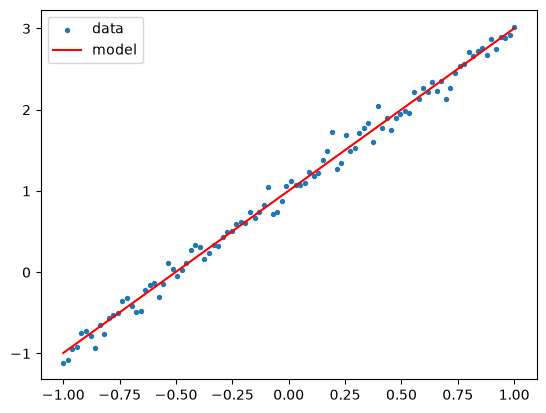

In [8]:
with torch.no_grad():
    plt.scatter(X, Y, s=8, label="data")
    plt.plot(X, model(X), color="red", label="model")
plt.legend()
plt.show()

## 7. 학습률(learning rate)의 영향

너무 작으면 느리고, 너무 크면 발산한다. 실전에서는 학습률에 덜 민감한 `Adam` / `AdamW`를 많이 쓴다.

In [9]:
for lr in [0.01, 0.1, 0.5, 1.1]:
    torch.manual_seed(0)
    m = nn.Linear(1, 1)
    opt = torch.optim.SGD(m.parameters(), lr=lr)
    for _ in range(50):
        opt.zero_grad()
        l = loss_fn(m(X), Y)
        l.backward()
        opt.step()
    print(f"SGD  lr={lr:<5} 50 step 후 loss = {l.item():.4f}")

torch.manual_seed(0)
m = nn.Linear(1, 1)
opt = torch.optim.Adam(m.parameters(), lr=0.1)
for _ in range(50):
    opt.zero_grad()
    l = loss_fn(m(X), Y)
    l.backward()
    opt.step()
print(f"Adam lr=0.1   50 step 후 loss = {l.item():.4f}")

SGD  lr=0.01  50 step 후 loss = 0.7427
SGD  lr=0.1   50 step 후 loss = 0.0119
SGD  lr=0.5   50 step 후 loss = 0.0105
SGD  lr=1.1   50 step 후 loss = 12557376.0000
Adam lr=0.1   50 step 후 loss = 0.0141
